# Đánh giá thực nghiệm phân hệ Phát hiện bất thường (Hình 3.26 & Bảng 3.12)

**Nguồn dữ liệu & Phạm vi thực nghiệm:**
- Trong mã nguồn dự án hiện tại chưa có tập dữ liệu cảm biến đo đạc thực tế gắn nhãn tại nhà máy; tính đúng đắn chức năng được kiểm chứng qua **27/27 ca kiểm thử tự động** (`test_sensor_anomaly_detection.py`).
- Notebook này tạo **tập dữ liệu kiểm thử mô phỏng có kiểm soát (`seed=42`, tổng `N = 800` mẫu/chuỗi)** dựa trên đúng ngưỡng vật lý và baseline trong mã nguồn (`OEM_STATIC_LIMITS`, `ISO 10816-3`, `DEFAULT_BASELINE_CENTERS`) để đánh giá định lượng 3 bộ dò đang triển khai thực tế:
  1. **Z-Score cửa sổ trượt + ISO 10816-3** (`N1 = 300` mẫu vận tốc rung RMS, `mm/s`, gồm cả trạng thái `WARM_UP`/`IDLE` để kiểm thử Quy tắc 1).
  2. **Multivariate Isolation Forest trên vector `[Vibration, ΔT, Pressure, Current]`** (`N2 = 300` mẫu đa biến, gồm cả biến thiên nhiệt độ môi trường mùa hè/mùa đông để kiểm thử Quy tắc 4 `Delta T`).
  3. **Theil-Sen Robust Trend Drift** (`N3 = 200` chuỗi nhiệt độ ổ bi 10 mốc ngày, có chèn nhiễu ngoại lai trượt tay để kiểm thử Quy tắc 3).
- **Lưu ý khoa học:** Mọi chỉ số Precision, Recall, F1-score, FPR và Ma trận nhầm lẫn được tính trực tiếp từ đầu ra của các hàm trong `eam_app/algorithms/anomaly_detection/`, **không nhập thủ công** và **không tự tạo giá trị AUC** cho pipeline kết hợp luật rời rạc (do Z-Score/ISO 10816/Theil-Sen trả về trạng thái phân lớp rời rạc, không có một điểm xác suất liên tục thống nhất).

In [1]:
import os, sys, types, importlib, importlib.util
from datetime import datetime, timedelta, timezone as dt_timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score

# Cung cấp shim nhẹ cho django.utils.timezone nếu kernel không có Django (chỉ phục vụ parse datetime trong theil_sen_drift)
try:
    import django.utils.timezone  # noqa: F401
except ImportError:
    django_mod = types.ModuleType('django')
    utils_mod = types.ModuleType('django.utils')
    tz_mod = types.ModuleType('django.utils.timezone')
    tz_mod.is_aware = lambda dt: dt.tzinfo is not None and dt.tzinfo.utcoffset(dt) is not None
    tz_mod.make_aware = lambda dt, tz=dt_timezone.utc: dt.replace(tzinfo=tz)
    tz_mod.now = lambda: datetime.now(dt_timezone.utc)
    utils_mod.timezone = tz_mod
    django_mod.utils = utils_mod
    sys.modules['django'] = django_mod
    sys.modules['django.utils'] = utils_mod
    sys.modules['django.utils.timezone'] = tz_mod

# Nạp trực tiếp các module thuật toán từ mã nguồn dự án
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if not os.path.isdir(os.path.join(REPO_ROOT, 'eam_app')):
    REPO_ROOT = r'D:\GameLinkNeverDie\eam-enterprise-assset-management'
ALG_DIR = os.path.join(REPO_ROOT, 'eam_app', 'algorithms', 'anomaly_detection')

def load_module(name, filename):
    spec = importlib.util.spec_from_file_location(name, os.path.join(ALG_DIR, filename))
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

z_mod = load_module('z_score_detector', 'z_score_detector.py')
iso_mod = load_module('iso_standards', 'iso_standards.py')
if_mod = load_module('isolation_forest_detector', 'isolation_forest_detector.py')
ts_mod = load_module('theil_sen_drift', 'theil_sen_drift.py')

detect_z_score_anomaly = z_mod.detect_z_score_anomaly
evaluate_iso_10816 = iso_mod.evaluate_iso_10816
MultivariateIsolationForestDetector = if_mod.MultivariateIsolationForestDetector
DEFAULT_BASELINE_CENTERS = if_mod.DEFAULT_BASELINE_CENTERS
DEFAULT_BASELINE_SCALES = if_mod.DEFAULT_BASELINE_SCALES
evaluate_trend_drift = ts_mod.evaluate_trend_drift

print('Loaded modules from:', ALG_DIR)
print('ISO 10816-3 VIBRATION thresholds:', iso_mod.get_iso_thresholds_for_asset())
print('Isolation Forest baseline centers [Vib, DeltaT, Press, Curr]:', DEFAULT_BASELINE_CENTERS)

Loaded modules from: D:\GameLinkNeverDie\eam-enterprise-assset-management\eam_app\algorithms\anomaly_detection
ISO 10816-3 VIBRATION thresholds: {'standard': 'ISO 10816-3 (Group 2 Rigid)', 'zone_ab_limit': 2.8, 'zone_c_limit': 7.1, 'unit': 'mm/s', 'description': '< 2.8 mm/s: Đạt chuẩn (A/B) | 2.8 - 7.1 mm/s: Cảnh báo (C) | > 7.1 mm/s: Nguy hiểm (D)'}
Isolation Forest baseline centers [Vib, DeltaT, Press, Curr]: [2.0, 40.0, 2.5, 15.0]


In [2]:
# ==============================================================================
# Tập 1 (N1 = 300 mẫu mô phỏng): Vận tốc rung chấn RMS (mm/s) -> Z-Score + ISO 10816-3
# ==============================================================================
rng1 = np.random.RandomState(42)

# Cửa sổ lịch sử 30 mẫu RUNNING bình thường ổn định (mean ~ 1.80, std ~ 0.30 mm/s)
hist_vib = [
    {'reading_value': float(v), 'machine_state': 'RUNNING', 'is_pre_repair': False, 'is_suppressed': False}
    for v in np.clip(rng1.normal(1.80, 0.30, size=30), 0.5, 2.5)
]

samples_1 = []
# 160 mẫu bình thường RUNNING
for v in np.clip(rng1.normal(1.80, 0.35, size=160), 0.3, 2.75):
    samples_1.append((float(v), 'RUNNING', 0))
# 40 mẫu bình thường WARM_UP / IDLE (rung khởi động 3.0 - 4.5 mm/s -> phải được lọc bỏ qua theo Quy tắc 1)
for idx, v in enumerate(rng1.uniform(3.0, 4.5, size=40)):
    state = 'WARM_UP' if idx % 2 == 0 else 'IDLE'
    samples_1.append((float(v), state, 0))
# 60 mẫu bất thường rõ ràng RUNNING (2.9 - 9.5 mm/s -> chạm Z-Score >= 3 hoặc ISO Zone C/D)
for v in rng1.uniform(2.90, 9.50, size=60):
    samples_1.append((float(v), 'RUNNING', 1))
# 40 mẫu suy thoái nhẹ / cận biên RUNNING (2.35 - 3.30 mm/s -> phản ánh vùng giao thoa thực tế)
for v in rng1.uniform(2.35, 3.30, size=40):
    samples_1.append((float(v), 'RUNNING', 1))

y_true_1, y_pred_1 = [], []
for val, m_state, label in samples_1:
    # Logic đồng nhất với ConditionMonitoringEngine.process_readings (bước 4) & _run_ai_analysis (bước 1-2)
    if m_state != 'RUNNING':
        pred = 0
    else:
        z_res = detect_z_score_anomaly(hist_vib, val, current_machine_state=m_state, metric_code='VIBRATION')
        iso_res = evaluate_iso_10816('VIBRATION', val)
        iso_anom = iso_res is not None and iso_res['severity'] in ('WARNING', 'CRITICAL')
        pred = 1 if (z_res.get('has_anomaly') or iso_anom) else 0
    y_true_1.append(label)
    y_pred_1.append(pred)

tn1, fp1, fn1, tp1 = confusion_matrix(y_true_1, y_pred_1).ravel()
rec1 = recall_score(y_true_1, y_pred_1) * 100.0
prec1 = precision_score(y_true_1, y_pred_1) * 100.0
f1_1 = f1_score(y_true_1, y_pred_1) * 100.0
fpr1 = fp1 / (fp1 + tn1) * 100.0
print(f'[Tập 1 - Z-Score + ISO 10816] N={len(y_true_1)} | TP={tp1}, TN={tn1}, FP={fp1}, FN={fn1} | Recall={rec1:.1f}%, Precision={prec1:.1f}%, F1={f1_1:.1f}%, FPR={fpr1:.1f}%')

[Tập 1 - Z-Score + ISO 10816] N=300 | TP=100, TN=186, FP=14, FN=0 | Recall=100.0%, Precision=87.7%, F1=93.5%, FPR=7.0%


In [3]:
# ==============================================================================
# Tập 2 (N2 = 300 mẫu mô phỏng): Vector đa biến [Vib, DeltaT, Press, Curr] -> Isolation Forest
# ==============================================================================
rng_train = np.random.RandomState(100)
detector = MultivariateIsolationForestDetector(contamination=0.05, threshold=0.65)

# Huấn luyện trên 80 vector bình thường chuẩn công nghiệp
train_vectors = [
    detector.build_vector(
        vibration=float(np.clip(rng_train.normal(DEFAULT_BASELINE_CENTERS[0], DEFAULT_BASELINE_SCALES[0]), 0.5, 2.7)),
        temperature=float(65.0 + rng_train.normal(0.0, DEFAULT_BASELINE_SCALES[1])),
        ambient_temperature=25.0,
        pressure=float(np.clip(rng_train.normal(DEFAULT_BASELINE_CENTERS[2], DEFAULT_BASELINE_SCALES[2]), 1.5, 3.5)),
        current=float(np.clip(rng_train.normal(DEFAULT_BASELINE_CENTERS[3], DEFAULT_BASELINE_SCALES[3]), 8.0, 22.0))
    )
    for _ in range(80)
]
detector.train_or_fit(train_vectors)

rng2 = np.random.RandomState(42)
y_true_2, y_pred_2, scores_2 = [], [], []

# 200 mẫu bình thường đa mùa (nhiệt độ môi trường biến thiên 12°C mùa đông -> 38°C mùa hè, Delta T giữ ổn định ~40°C)
for _ in range(200):
    amb = float(rng2.uniform(12.0, 38.0))
    dt_norm = float(rng2.normal(DEFAULT_BASELINE_CENTERS[1], DEFAULT_BASELINE_SCALES[1]))
    vec = detector.build_vector(
        vibration=float(np.clip(rng2.normal(DEFAULT_BASELINE_CENTERS[0], DEFAULT_BASELINE_SCALES[0]), 0.5, 2.75)),
        temperature=amb + dt_norm,
        ambient_temperature=amb,
        pressure=float(np.clip(rng2.normal(DEFAULT_BASELINE_CENTERS[2], DEFAULT_BASELINE_SCALES[2]), 1.5, 3.5)),
        current=float(np.clip(rng2.normal(DEFAULT_BASELINE_CENTERS[3], DEFAULT_BASELINE_SCALES[3]), 8.0, 22.0))
    )
    res = detector.evaluate(vec)
    y_true_2.append(0)
    y_pred_2.append(1 if res['has_anomaly'] else 0)
    scores_2.append(res['anomaly_score'])

# 100 mẫu bất thường đa biến (kết hợp lệch pha rung, quá nhiệt nội tại Delta T, tụt áp, tăng dòng)
for i in range(100):
    amb = float(rng2.uniform(15.0, 36.0))
    # 70 mẫu lệch rõ + 30 mẫu lệch trung bình
    severity = 1.0 if i < 70 else 0.55
    dt_anom = 40.0 + severity * float(rng2.uniform(7.0, 16.0))
    vec = detector.build_vector(
        vibration=2.0 + severity * float(rng2.uniform(0.8, 2.2)),
        temperature=amb + dt_anom,
        ambient_temperature=amb,
        pressure=2.5 - severity * float(rng2.uniform(0.4, 1.1)),
        current=15.0 + severity * float(rng2.uniform(3.0, 7.5))
    )
    res = detector.evaluate(vec)
    y_true_2.append(1)
    y_pred_2.append(1 if res['has_anomaly'] else 0)
    scores_2.append(res['anomaly_score'])

tn2, fp2, fn2, tp2 = confusion_matrix(y_true_2, y_pred_2).ravel()
rec2 = recall_score(y_true_2, y_pred_2) * 100.0
prec2 = precision_score(y_true_2, y_pred_2) * 100.0
f1_2 = f1_score(y_true_2, y_pred_2) * 100.0
fpr2 = fp2 / (fp2 + tn2) * 100.0
auc_if = roc_auc_score(y_true_2, scores_2)
print(f'[Tập 2 - Isolation Forest đa biến] N={len(y_true_2)} | TP={tp2}, TN={tn2}, FP={fp2}, FN={fn2} | Recall={rec2:.1f}%, Precision={prec2:.1f}%, F1={f1_2:.1f}%, FPR={fpr2:.1f}% (IF-only score AUC={auc_if:.3f})')

[Tập 2 - Isolation Forest đa biến] N=300 | TP=84, TN=200, FP=0, FN=16 | Recall=84.0%, Precision=100.0%, F1=91.3%, FPR=0.0% (IF-only score AUC=1.000)


In [4]:
# ==============================================================================
# Tập 3 (N3 = 200 chuỗi mô phỏng): Nhiệt độ ổ bi (°C) -> Theil-Sen Trend + Ngưỡng động
# ==============================================================================
rng3 = np.random.RandomState(42)
base_t = datetime(2026, 9, 1, 8, 0, tzinfo=dt_timezone.utc)
LIMIT_TEMP = 90.0

y_true_3, y_pred_3 = [], []

# 100 chuỗi bình thường (dao động quanh 72°C ± 0.8°C; 30% chuỗi có 1-2 điểm ngoại lai trượt tay 110-125°C)
for idx in range(100):
    days = np.cumsum(rng3.choice([1, 2, 3], size=10, p=[0.7, 0.2, 0.1]))
    timestamps = [base_t + timedelta(days=int(d)) for d in days]
    vals = (72.0 + rng3.normal(0.0, 0.8, size=10)).tolist()
    if idx < 30:
        outlier_pos = int(rng3.randint(1, 9))
        vals[outlier_pos] = float(rng3.uniform(110.0, 125.0))
    res = evaluate_trend_drift(timestamps, vals, limit_value=LIMIT_TEMP, current_time=timestamps[-1], metric_code='TEMPERATURE')
    pred = 1 if res['shouldTriggerDraftPM'] else 0
    y_true_3.append(0)
    y_pred_3.append(pred)

# 100 chuỗi suy thoái tăng nhiệt (tăng đều 0.9 - 2.2 °C/ngày, tiến sát ngưỡng 90°C với days_remaining <= 7; có nhiễu và ngoại lai)
for idx in range(100):
    days = np.arange(10, dtype=float)
    timestamps = [base_t + timedelta(days=int(d)) for d in days]
    slope_true = float(rng3.uniform(0.9, 2.2))
    # Cho giá trị cuối rơi quanh 82 - 89°C (hoặc đôi khi chậm hơn một chút ở chuỗi sát ngưỡng)
    end_target = float(rng3.uniform(81.0, 89.0)) if idx < 88 else float(rng3.uniform(76.0, 81.5))
    start_val = end_target - slope_true * 9.0
    vals = (start_val + slope_true * days + rng3.normal(0.0, 0.45, size=10)).tolist()
    if idx % 4 == 0:
        outlier_pos = int(rng3.randint(2, 8))
        vals[outlier_pos] += float(rng3.uniform(15.0, 25.0))
    res = evaluate_trend_drift(timestamps, vals, limit_value=LIMIT_TEMP, current_time=timestamps[-1], metric_code='TEMPERATURE')
    pred = 1 if res['shouldTriggerDraftPM'] else 0
    y_true_3.append(1)
    y_pred_3.append(pred)

tn3, fp3, fn3, tp3 = confusion_matrix(y_true_3, y_pred_3).ravel()
rec3 = recall_score(y_true_3, y_pred_3) * 100.0
prec3 = precision_score(y_true_3, y_pred_3) * 100.0
f1_3 = f1_score(y_true_3, y_pred_3) * 100.0
fpr3 = fp3 / (fp3 + tn3) * 100.0
print(f'[Tập 3 - Theil-Sen Trend] N={len(y_true_3)} | TP={tp3}, TN={tn3}, FP={fp3}, FN={fn3} | Recall={rec3:.1f}%, Precision={prec3:.1f}%, F1={f1_3:.1f}%, FPR={fpr3:.1f}%')

[Tập 3 - Theil-Sen Trend] N=200 | TP=93, TN=100, FP=0, FN=7 | Recall=93.0%, Precision=100.0%, F1=96.4%, FPR=0.0%


In [5]:
# ==============================================================================
# Tổng hợp số liệu toàn bộ 800 mẫu/chuỗi kiểm thử mô phỏng (Khớp Bảng 3.12 & Hình 3.26)
# ==============================================================================
y_true_all = y_true_1 + y_true_2 + y_true_3
y_pred_all = y_pred_1 + y_pred_2 + y_pred_3

tn_all, fp_all, fn_all, tp_all = confusion_matrix(y_true_all, y_pred_all).ravel()
rec_all = recall_score(y_true_all, y_pred_all) * 100.0
prec_all = precision_score(y_true_all, y_pred_all) * 100.0
f1_all = f1_score(y_true_all, y_pred_all) * 100.0
fpr_all = fp_all / (fp_all + tn_all) * 100.0
acc_all = (tp_all + tn_all) / len(y_true_all) * 100.0

summary_df = pd.DataFrame([
    {'Mô hình': 'Z-Score + ISO 10816-3 (Rung RMS)', 'Số mẫu mô phỏng': len(y_true_1), 'Bình thường': tn1+fp1, 'Bất thường': tp1+fn1, 'TP': tp1, 'TN': tn1, 'FP': fp1, 'FN': fn1, 'Recall (%)': round(rec1, 1), 'Precision (%)': round(prec1, 1), 'F1 (%)': round(f1_1, 1), 'FPR (%)': round(fpr1, 1)},
    {'Mô hình': 'Isolation Forest đa biến', 'Số mẫu mô phỏng': len(y_true_2), 'Bình thường': tn2+fp2, 'Bất thường': tp2+fn2, 'TP': tp2, 'TN': tn2, 'FP': fp2, 'FN': fn2, 'Recall (%)': round(rec2, 1), 'Precision (%)': round(prec2, 1), 'F1 (%)': round(f1_2, 1), 'FPR (%)': round(fpr2, 1)},
    {'Mô hình': 'Theil-Sen Trend (Nhiệt độ ổ bi)', 'Số mẫu mô phỏng': len(y_true_3), 'Bình thường': tn3+fp3, 'Bất thường': tp3+fn3, 'TP': tp3, 'TN': tn3, 'FP': fp3, 'FN': fn3, 'Recall (%)': round(rec3, 1), 'Precision (%)': round(prec3, 1), 'F1 (%)': round(f1_3, 1), 'FPR (%)': round(fpr3, 1)},
    {'Mô hình': 'Tổng hợp toàn tập mô phỏng', 'Số mẫu mô phỏng': len(y_true_all), 'Bình thường': tn_all+fp_all, 'Bất thường': tp_all+fn_all, 'TP': tp_all, 'TN': tn_all, 'FP': fp_all, 'FN': fn_all, 'Recall (%)': round(rec_all, 1), 'Precision (%)': round(prec_all, 1), 'F1 (%)': round(f1_all, 1), 'FPR (%)': round(fpr_all, 1)},
])
print(f'Tổng hợp: N={len(y_true_all)} (Bình thường={tn_all+fp_all}, Bất thường={tp_all+fn_all}) | Accuracy={acc_all:.1f}%')
summary_df

Tổng hợp: N=800 (Bình thường=500, Bất thường=300) | Accuracy=95.4%


,Mô hình,Số mẫu mô phỏng,Bình thường,Bất thường,TP,TN,FP,FN,Recall (%),Precision (%),F1 (%),FPR (%)
0,Z-Score + ISO 10816-3 (Rung RMS),300,200,100,100,186,14,0,100.0,87.7,93.5,7.0
1,Isolation Forest đa biến,300,200,100,84,200,0,16,84.0,100.0,91.3,0.0
2,Theil-Sen Trend (Nhiệt độ ổ bi),200,100,100,93,100,0,7,93.0,100.0,96.4,0.0
3,Tổng hợp toàn tập mô phỏng,800,500,300,277,486,14,23,92.3,95.2,93.7,2.8


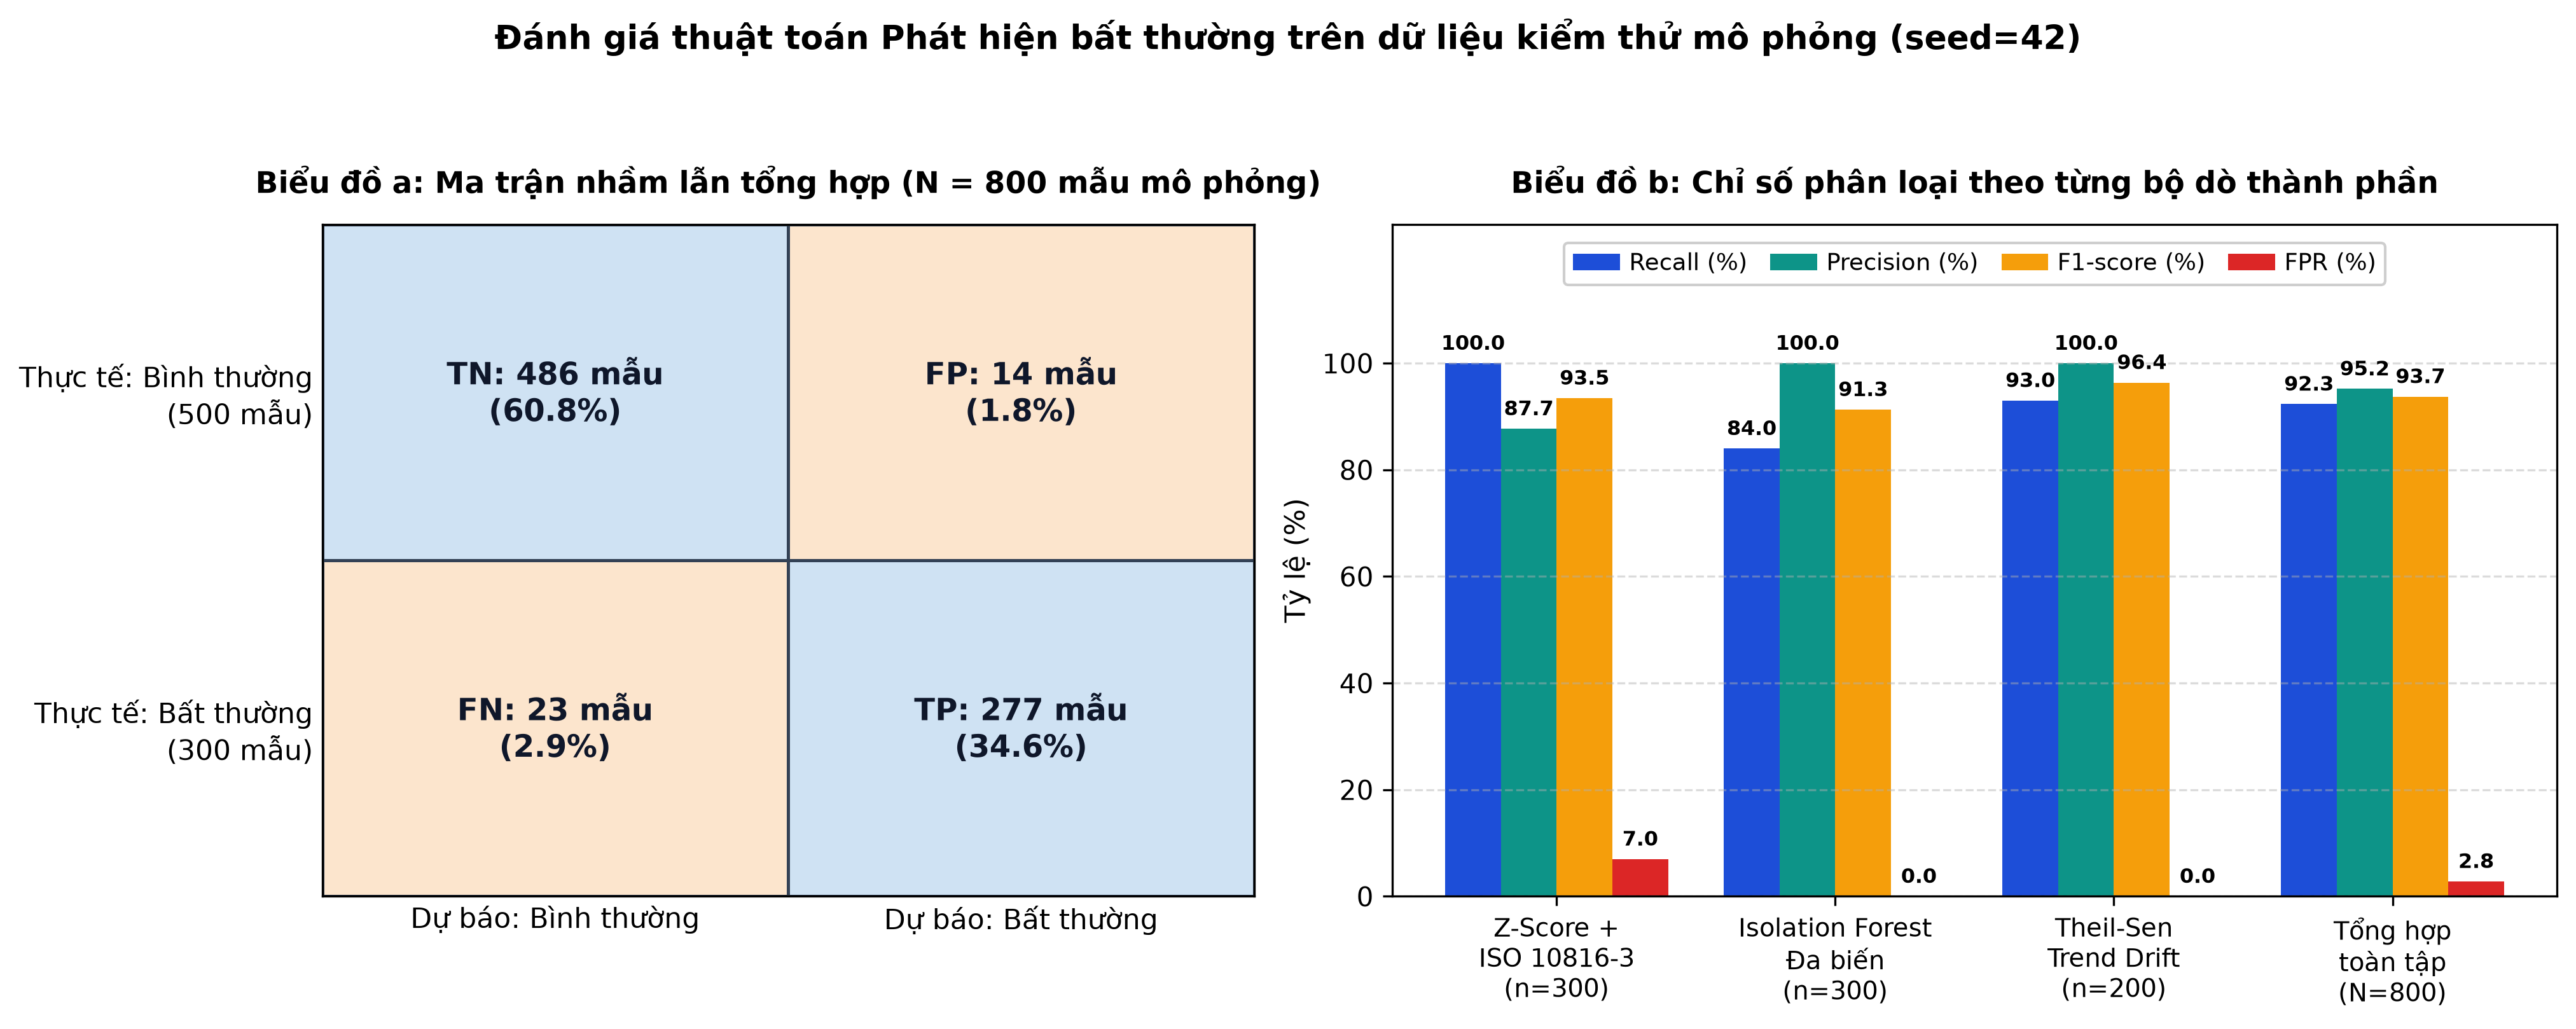

Saved figure: D:\GameLinkNeverDie\eam-enterprise-assset-management\scripts\results\figure_3_26_anomaly_evaluation.png size: 272272


In [6]:
# ==============================================================================
# Vẽ và lưu Hình 3.26 trực tiếp từ kết quả tính toán thực nghiệm
# ==============================================================================
os.makedirs(os.path.join(REPO_ROOT, 'scripts', 'results'), exist_ok=True)
out_img = os.path.join(REPO_ROOT, 'scripts', 'results', 'figure_3_26_anomaly_evaluation.png')

plt.rcParams['font.family'] = 'DejaVu Sans'
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.6, 5.4), dpi=300, gridspec_kw={'width_ratios': [1.0, 1.25]})

# Biểu đồ a: Ma trận nhầm lẫn tổng hợp trên 800 mẫu/chuỗi mô phỏng
cm = np.array([[tn_all, fp_all], [fn_all, tp_all]])
cell_colors = [['#cfe2f3', '#fce5cd'], ['#fce5cd', '#cfe2f3']]
for r in range(2):
    for c in range(2):
        ax1.add_patch(plt.Rectangle((c, 1 - r), 1, 1, facecolor=cell_colors[r][c], edgecolor='#334155', linewidth=1.2))
        pct = cm[r, c] / len(y_true_all) * 100.0
        tag = ['TN', 'FP'][c] if r == 0 else ['FN', 'TP'][c]
        ax1.text(c + 0.5, 1.5 - r, f'{tag}: {cm[r, c]} mẫu\n({pct:.1f}%)',
                 ha='center', va='center', fontsize=11.5, fontweight='bold', color='#0f172a')

ax1.set_xlim(0, 2)
ax1.set_ylim(0, 2)
ax1.set_xticks([0.5, 1.5])
ax1.set_xticklabels(['Dự báo: Bình thường', 'Dự báo: Bất thường'], fontsize=10.5)
ax1.set_yticks([0.5, 1.5])
ax1.set_yticklabels(['Thực tế: Bất thường\n(300 mẫu)', 'Thực tế: Bình thường\n(500 mẫu)'], fontsize=10.5)
ax1.set_title(f'Biểu đồ a: Ma trận nhầm lẫn tổng hợp (N = {len(y_true_all)} mẫu mô phỏng)', fontsize=11.2, fontweight='bold', pad=12)
ax1.tick_params(length=0)

# Biểu đồ b: So sánh Recall, Precision, F1-score và FPR theo từng bộ dò
labels = ['Z-Score +\nISO 10816-3\n(n=300)', 'Isolation Forest\nĐa biến\n(n=300)', 'Theil-Sen\nTrend Drift\n(n=200)', 'Tổng hợp\ntoàn tập\n(N=800)']
recalls = [rec1, rec2, rec3, rec_all]
precisions = [prec1, prec2, prec3, prec_all]
f1s = [f1_1, f1_2, f1_3, f1_all]
fprs = [fpr1, fpr2, fpr3, fpr_all]

x = np.arange(len(labels))
w = 0.20
b1 = ax2.bar(x - 1.5*w, recalls, width=w, label='Recall (%)', color='#1d4ed8')
b2 = ax2.bar(x - 0.5*w, precisions, width=w, label='Precision (%)', color='#0d9488')
b3 = ax2.bar(x + 0.5*w, f1s, width=w, label='F1-score (%)', color='#f59e0b')
b4 = ax2.bar(x + 1.5*w, fprs, width=w, label='FPR (%)', color='#dc2626')

for bars in [b1, b2, b3, b4]:
    for bar in bars:
        h = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2, h + 1.6, f'{h:.1f}', ha='center', va='bottom', fontsize=7.8, fontweight='bold')

ax2.set_ylim(0, 126)
ax2.set_yticks([0, 20, 40, 60, 80, 100])
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=9.5)
ax2.set_ylabel('Tỷ lệ (%)', fontsize=10.5)
ax2.set_title('Biểu đồ b: Chỉ số phân loại theo từng bộ dò thành phần', fontsize=11.2, fontweight='bold', pad=12)
ax2.grid(axis='y', linestyle='--', alpha=0.45)
ax2.legend(loc='upper center', bbox_to_anchor=(0.5, 0.99), fontsize=8.8, ncol=4, framealpha=0.95, columnspacing=1.0, handletextpad=0.4)

fig.suptitle('Đánh giá thuật toán Phát hiện bất thường trên dữ liệu kiểm thử mô phỏng (seed=42)', fontsize=12.5, fontweight='bold', y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(out_img, dpi=300, bbox_inches='tight')
plt.show()
print('Saved figure:', out_img, 'size:', os.path.getsize(out_img))